# Adım 3: Kalibrasyon, Test Değerlendirmesi, Uzmana Yönlendirme Analizi ve Grad-CAM

Bu defter, Adım 2'de eğittiğimiz **cnn_b0_v3** modelini kullanır ve şunları yapar:

1. **Kalibrasyon (sıcaklık ölçekleme):** Model "%90 eminim" dediğinde gerçekten yaklaşık %90 haklı olsun. Bulanık mantık (Adım 8) bu güven değerine dayanacak.
2. **Test kümesi, ilk ve tek kez açılır:** Bütün ayarlar (sıcaklık T ve karar ayarı τ) yalnızca doğrulama kümesinde belirlendi ve donduruldu. Test sonuçları tezde raporlanacak gerçek sonuçlardır.
3. **Güven aralıkları:** Sonuçların ne kadar kesin olduğunu görmek için lezyon bazlı bootstrap.
4. **Uzmana yönlendirme ön analizi:** Model yalnızca emin olduğu vakalarda karar verirse doğruluk ne olur, kaç melanom kaçırılır? Projenin hikâyesini anlatan ilk grafik.
5. **Grad-CAM ısı haritaları:** Model gerçekten lezyona mı bakıyor, yoksa cetvel, kıl, koyu kenar gibi ipuçlarına mı?

**İki ayrı kavram (karıştırmamak önemli):**
- **Olasılık (dürüst güven):** softmax(logit / T). Gerçek dünyadaki dağılıma göre kalibre edilmiş, "ne kadar eminim" sorusunun cevabı.
- **Karar kuralı:** argmax(logit − τ × log(sınıf oranı)). Melanom gibi nadir ve tehlikeli sınıfları kaçırmamak için "ben" yönündeki eğilimi düzeltir.

Sistem ikisini birlikte kullanır: kararı karar kuralıyla verir, o karara ne kadar güvenileceğini dürüst olasılıkla söyler.

**Çalışma zamanı:** GPU (T4 yeterli). Süre yaklaşık 10-15 dakika.

## 1. Ortam, model ve veri

In [1]:
import os, json, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.optimize import minimize_scalar
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

MODEL_ADI = 'cnn_b0_v3'          # Adım 2'de seçtiğimiz model
BATCH = 64
TOHUM = 42
rng = np.random.default_rng(TOHUM)
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')

with open(f'{PROJE}/results/02_{MODEL_ADI}_dogrulama_metrikleri.json', encoding='utf-8') as f:
    adim2 = json.load(f)
IMG, SINIFLAR, TAU = adim2['img'], adim2['siniflar'], adim2['tau']
SINIF_ADI = {'akiec': 'Aktinik keratoz', 'bcc': 'Bazal hücreli karsinom', 'bkl': 'Benign keratoz',
             'df': 'Dermatofibrom', 'mel': 'Melanom', 'nv': 'Melanositik nevüs (ben)', 'vasc': 'Vasküler lezyon'}
ETIKET = [SINIF_ADI[s] for s in SINIFLAR]
MEL = SINIFLAR.index('mel')
os.makedirs(f'{PROJE}/results', exist_ok=True)

print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'YOK')
print(f'Model: {MODEL_ADI} | Giriş boyutu: {IMG} | Adım 2\'de seçilen τ: {TAU}')
model = keras.models.load_model(f'{PROJE}/models/{MODEL_ADI}.keras')
print('Model yüklendi.')

Mounted at /content/drive
TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model: cnn_b0_v3 | Giriş boyutu: 224 | Adım 2'de seçilen τ: 1.05
Model yüklendi.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 232 variables whereas the saved optimizer has 236 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [2]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists('/content/ham'):
    !unzip -q -n "{ZIP}" -d /content/ham
GORUNTU_KOKU = '/content/ham'

yollar = {}
for p in glob.glob(f'{GORUNTU_KOKU}/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)
meta['y'] = meta['dx'].map({s: i for i, s in enumerate(SINIFLAR)})
assert meta['path'].notna().all()
assert meta.groupby('lesion_id')['split'].nunique().max() == 1

egitim    = meta[meta['split'] == 'egitim'].reset_index(drop=True)
dogrulama = meta[meta['split'] == 'dogrulama'].reset_index(drop=True)
test      = meta[meta['split'] == 'test'].reset_index(drop=True)
y_dog, y_test = dogrulama['y'].values, test['y'].values

def oku(yol):
    g = tf.io.decode_jpeg(tf.io.read_file(yol), channels=3)
    return tf.image.resize(g, (IMG, IMG))   # 0-255 aralığında float; model kendi ön işlemesini yapar

def veri_hatti(df):
    return (tf.data.Dataset.from_tensor_slices(df['path'].values)
            .map(oku, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE))

# Eğitimdeki sınıf oranları: karar kuralı (logit ayarı) bunları kullanır
oncel = np.bincount(egitim['y'], minlength=len(SINIFLAR)) / len(egitim)
LOG_ONCEL = np.log(oncel)

# Doğrulama logitlerini yeniden hesapla ve Adım 2'de kaydedilenlerle karşılaştır (aynı model mi?)
logit_dog = model.predict(veri_hatti(dogrulama), verbose=0).astype('float64')
kayitli = np.load(f'{PROJE}/models/{MODEL_ADI}_dogrulama_logit.npy')
print('Eğitim:', len(egitim), '| Doğrulama:', len(dogrulama), '| Test:', len(test))
print(f'Doğrulama logitleri Adım 2 ile tutarlı mı: {np.allclose(logit_dog, kayitli, atol=0.05)} (en büyük fark {np.abs(logit_dog - kayitli).max():.4f})')

Eğitim: 7054 | Doğrulama: 1464 | Test: 1497
Doğrulama logitleri Adım 2 ile tutarlı mı: False (en büyük fark 0.1416)


## 2. Kalibrasyon: sıcaklık ölçekleme
Derin ağlar genellikle **aşırı özgüvenlidir**: "%95 eminim" dedikleri vakaların belki yalnızca %85'inde haklıdırlar.

**Sıcaklık ölçekleme** tek bir sayı (T) öğrenir ve bütün logitleri ona böler: olasılık = softmax(logit / T).
- T > 1: model fazla özgüvenliymiş, güveni yumuşatılır.
- T < 1: model fazla çekingenmiş.
- Tahmin edilen sınıf değişmez; yalnızca güven değerleri düzelir.

T doğrulama kümesinde, **negatif log-olabilirliği** (NLL, kayıp) en küçük yapacak şekilde seçilir.

**ECE (beklenen kalibrasyon hatası):** Tahminler güvenlerine göre 15 kutuya ayrılır; her kutuda "ortalama güven" ile "gerçek doğruluk" arasındaki fark ölçülür. 0 mükemmel kalibrasyon demektir.

In [3]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def nll(logit, y, T=1.0):
    p = softmax(logit / T)
    return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

def ece(olasilik, y, kutu=15):
    guven, tahmin = olasilik.max(1), olasilik.argmax(1)
    sinirlar = np.linspace(0, 1, kutu + 1)
    hata = 0.0
    for a, b in zip(sinirlar[:-1], sinirlar[1:]):
        m = (guven > a) & (guven <= b)
        if m.any():
            hata += m.mean() * abs((tahmin[m] == y[m]).mean() - guven[m].mean())
    return float(hata)

sonuc = minimize_scalar(lambda logT: nll(logit_dog, y_dog, np.exp(logT)), bounds=(-3, 3), method='bounded')
T = float(np.exp(sonuc.x))

p_dog_ham, p_dog_kal = softmax(logit_dog), softmax(logit_dog / T)
print(f'Seçilen sıcaklık T = {T:.3f}  ({"model fazla özgüvenliymiş" if T > 1 else "model fazla çekingenmiş"})\n')
print(pd.DataFrame({'olcut': ['NLL (kayıp)', 'ECE'],
                    'kalibrasyon_oncesi': [nll(logit_dog, y_dog), ece(p_dog_ham, y_dog)],
                    'kalibrasyon_sonrasi': [nll(logit_dog, y_dog, T), ece(p_dog_kal, y_dog)]}).round(4).to_string(index=False))
print('\nNot: Bu değerler T\'nin seçildiği doğrulama kümesinde; tarafsız ölçüm aşağıda test kümesinde.')

Seçilen sıcaklık T = 1.051  (model fazla özgüvenliymiş)

      olcut  kalibrasyon_oncesi  kalibrasyon_sonrasi
NLL (kayıp)              0.4604               0.4598
        ECE              0.0184               0.0155

Not: Bu değerler T'nin seçildiği doğrulama kümesinde; tarafsız ölçüm aşağıda test kümesinde.


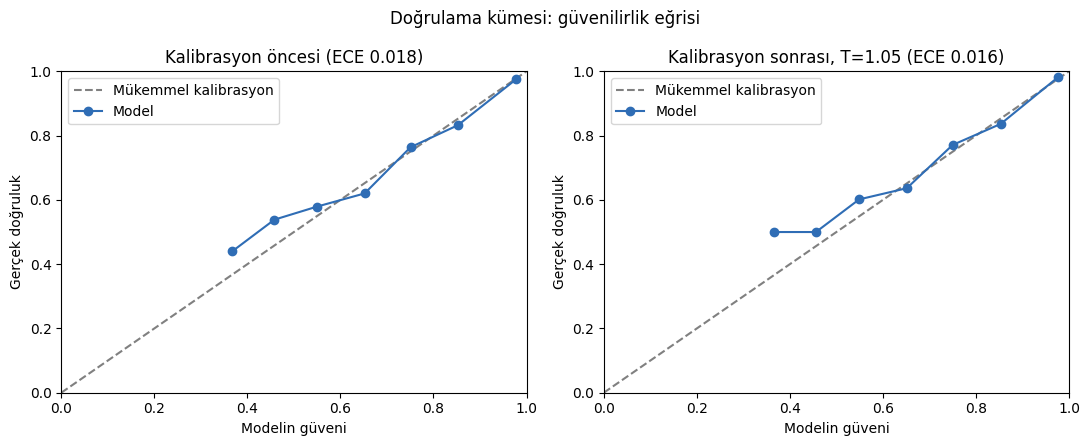

In [4]:
def guvenilirlik_egrisi(ax, olasilik, y, baslik, kutu=10):
    guven, dogru = olasilik.max(1), (olasilik.argmax(1) == y)
    sinirlar = np.linspace(0, 1, kutu + 1)
    orta, dogruluk, sayi = [], [], []
    for a, b in zip(sinirlar[:-1], sinirlar[1:]):
        m = (guven > a) & (guven <= b)
        if m.sum() >= 5:
            orta.append(guven[m].mean()); dogruluk.append(dogru[m].mean()); sayi.append(m.sum())
    ax.plot([0, 1], [0, 1], '--', color='gray', label='Mükemmel kalibrasyon')
    ax.plot(orta, dogruluk, 'o-', color='#2F6DB5', label='Model')
    ax.set_xlabel('Modelin güveni'); ax.set_ylabel('Gerçek doğruluk'); ax.set_title(baslik)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc='upper left')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
guvenilirlik_egrisi(ax[0], p_dog_ham, y_dog, f'Kalibrasyon öncesi (ECE {ece(p_dog_ham, y_dog):.3f})')
guvenilirlik_egrisi(ax[1], p_dog_kal, y_dog, f'Kalibrasyon sonrası, T={T:.2f} (ECE {ece(p_dog_kal, y_dog):.3f})')
plt.suptitle('Doğrulama kümesi: güvenilirlik eğrisi'); plt.tight_layout()
plt.savefig(f'{PROJE}/results/03_kalibrasyon_dogrulama.png', dpi=150); plt.show()

## 3. Test kümesi (ilk ve tek açılış)
Buradan sonra **hiçbir ayar değiştirilmez.** T ve τ doğrulama kümesinde belirlendi ve donduruldu. Test sonucunu görüp ayar değiştirmek, sonuçları sahte biçimde iyileştirir; bu yüzden bu hücre yalnızca bir kez çalıştırılmalıdır (aynı ayarlarla tekrar çalıştırmak sorun değil, sonuç değişmez).

İki durum raporlanır:
- **Ayarsız:** Modelin ham kararı (en yüksek olasılıklı sınıf).
- **Ayarlı:** Karar kuralı uygulanmış (τ ile, melanomu kaçırmamaya yönelik).

In [5]:
DONMUS = {'T': T, 'tau': TAU}
print('Dondurulan ayarlar:', {k: round(v, 3) for k, v in DONMUS.items()})

logit_test = model.predict(veri_hatti(test), verbose=0).astype('float64')
np.save(f'{PROJE}/models/{MODEL_ADI}_test_logit.npy', logit_test)
np.save(f'{PROJE}/models/{MODEL_ADI}_test_y.npy', y_test)

p_test = softmax(logit_test / T)                       # dürüst (kalibre) olasılık
tahmin_ham = logit_test.argmax(1)                      # ayarsız karar
tahmin_ayarli = (logit_test - TAU * LOG_ONCEL).argmax(1)   # ayarlı karar

def olc(y, tahmin, p):
    rapor = classification_report(y, tahmin, labels=range(len(SINIFLAR)), target_names=ETIKET,
                                  output_dict=True, zero_division=0)
    return {'dengeli_dogruluk': balanced_accuracy_score(y, tahmin),
            'dogruluk': float((tahmin == y).mean()),
            'makro_f1': f1_score(y, tahmin, average='macro'),
            'makro_auc': roc_auc_score(y, p, multi_class='ovr', average='macro', labels=range(len(SINIFLAR))),
            'melanom_duyarliligi': rapor['Melanom']['recall'],
            'melanom_kesinligi': rapor['Melanom']['precision'],
            'nevus_duyarliligi': rapor['Melanositik nevüs (ben)']['recall']}

test_ham, test_ayarli = olc(y_test, tahmin_ham, p_test), olc(y_test, tahmin_ayarli, p_test)
print('\nTEST SONUÇLARI')
print(pd.DataFrame({'ayarsiz': test_ham, 'ayarli (τ)': test_ayarli}).round(3).to_string())
print(f'\nTest ECE: kalibrasyon öncesi {ece(softmax(logit_test), y_test):.4f} -> sonrası {ece(p_test, y_test):.4f}')
print(f'Test NLL: kalibrasyon öncesi {nll(logit_test, y_test):.4f} -> sonrası {nll(logit_test, y_test, T):.4f}')

Dondurulan ayarlar: {'T': 1.051, 'tau': 1.05}

TEST SONUÇLARI
                     ayarsiz  ayarli (τ)
dengeli_dogruluk       0.658       0.683
dogruluk               0.804       0.644
makro_f1               0.648       0.561
makro_auc              0.960       0.960
melanom_duyarliligi    0.565       0.702
melanom_kesinligi      0.642       0.391
nevus_duyarliligi      0.882       0.616

Test ECE: kalibrasyon öncesi 0.0183 -> sonrası 0.0166
Test NLL: kalibrasyon öncesi 0.5426 -> sonrası 0.5398


Sınıf bazında duyarlılık ve kesinlik (test)
                         ornek  duyarlilik_ayarsiz  duyarlilik_ayarli  kesinlik_ayarsiz  kesinlik_ayarli
Aktinik keratoz             51               0.471              0.490             0.615            0.410
Bazal hücreli karsinom      77               0.740              0.740             0.687            0.606
Benign keratoz             157               0.764              0.732             0.561            0.502
Dermatofibrom               22               0.591              0.773             0.302            0.102
Melanom                    168               0.565              0.702             0.642            0.391
Melanositik nevüs (ben)   1000               0.882              0.616             0.922            0.986
Vasküler lezyon             22               0.591              0.727             1.000            0.842


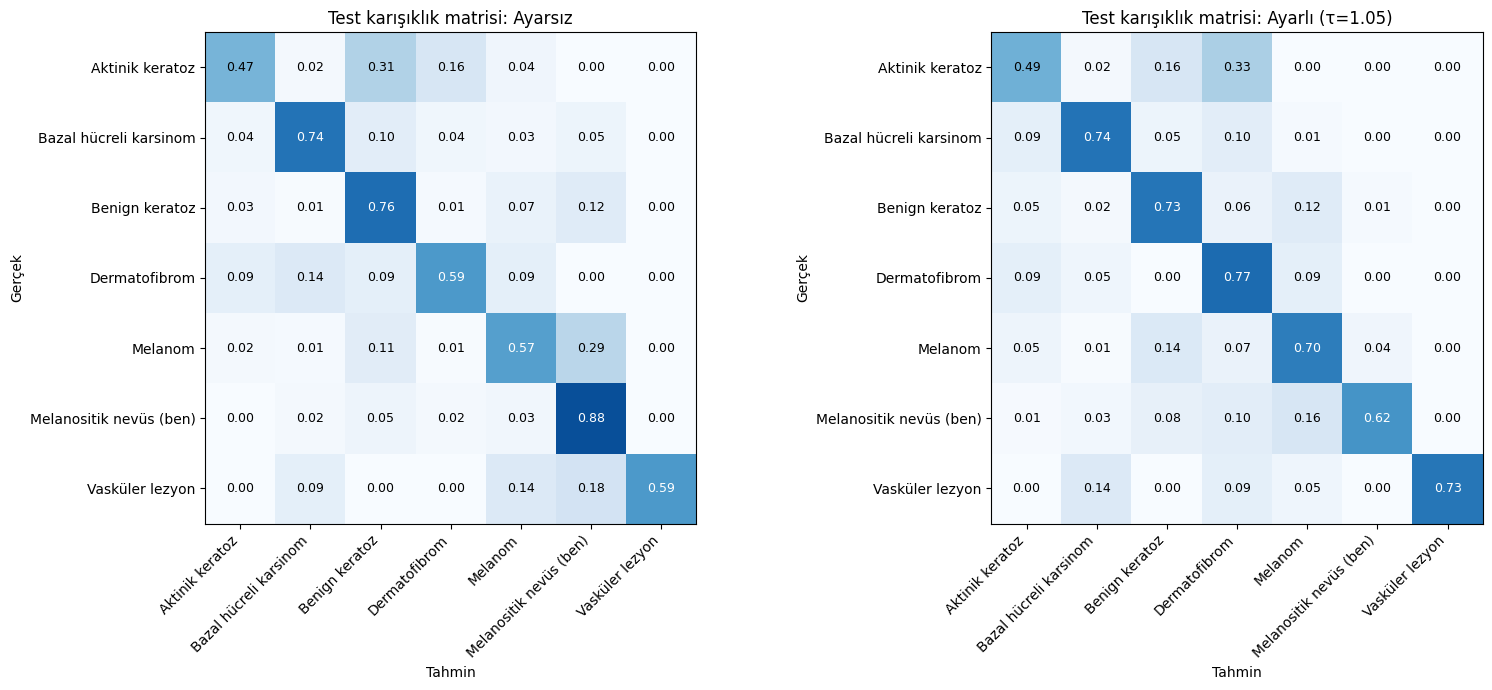

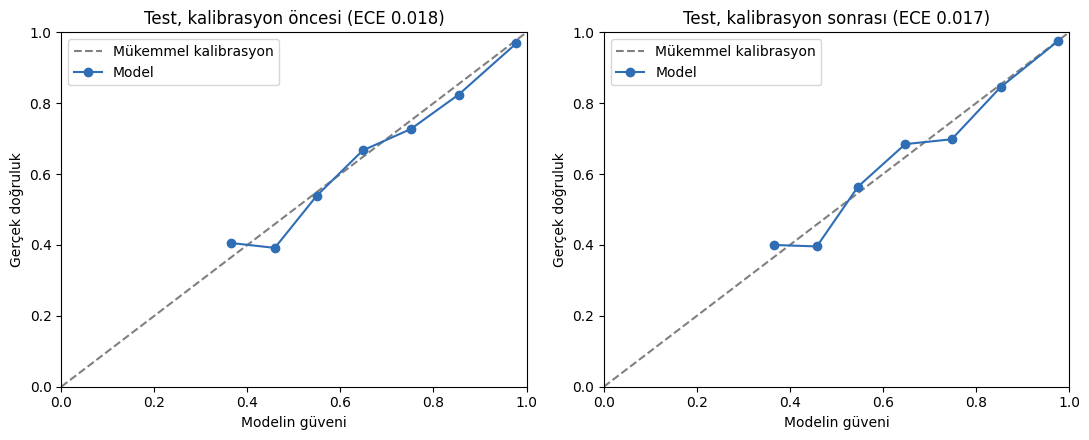

In [6]:
print('Sınıf bazında duyarlılık ve kesinlik (test)')
rh = classification_report(y_test, tahmin_ham, labels=range(len(SINIFLAR)), target_names=ETIKET, output_dict=True, zero_division=0)
ra = classification_report(y_test, tahmin_ayarli, labels=range(len(SINIFLAR)), target_names=ETIKET, output_dict=True, zero_division=0)
print(pd.DataFrame({'ornek': [int(rh[e]['support']) for e in ETIKET],
                    'duyarlilik_ayarsiz': [rh[e]['recall'] for e in ETIKET],
                    'duyarlilik_ayarli': [ra[e]['recall'] for e in ETIKET],
                    'kesinlik_ayarsiz': [rh[e]['precision'] for e in ETIKET],
                    'kesinlik_ayarli': [ra[e]['precision'] for e in ETIKET]}, index=ETIKET).round(3).to_string())

fig, eksen = plt.subplots(1, 2, figsize=(16, 7))
for ax, tah, baslik in [(eksen[0], tahmin_ham, 'Ayarsız'), (eksen[1], tahmin_ayarli, f'Ayarlı (τ={TAU})')]:
    km = confusion_matrix(y_test, tah, labels=range(len(SINIFLAR)), normalize='true')
    im = ax.imshow(km, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(ETIKET)), ETIKET, rotation=45, ha='right'); ax.set_yticks(range(len(ETIKET)), ETIKET)
    for i in range(len(ETIKET)):
        for j in range(len(ETIKET)):
            ax.text(j, i, f'{km[i, j]:.2f}', ha='center', va='center', color='white' if km[i, j] > 0.5 else 'black', fontsize=9)
    ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek'); ax.set_title(f'Test karışıklık matrisi: {baslik}')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/03_test_karisiklik_matrisi.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
guvenilirlik_egrisi(ax[0], softmax(logit_test), y_test, f'Test, kalibrasyon öncesi (ECE {ece(softmax(logit_test), y_test):.3f})')
guvenilirlik_egrisi(ax[1], p_test, y_test, f'Test, kalibrasyon sonrası (ECE {ece(p_test, y_test):.3f})')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/03_kalibrasyon_test.png', dpi=150); plt.show()

## 4. Güven aralıkları (lezyon bazlı bootstrap)
Test kümesi sonlu; başka bir test kümesi seçilseydi sonuçlar biraz farklı çıkardı. **Bootstrap**, test kümesinden rastgele yeniden örneklem alarak bu belirsizliği ölçer.

Aynı lezyonun görüntüleri birbirine çok benzediği için örnekleme **lezyon bazında** yapılır (bir lezyon seçilirse bütün görüntüleri gelir). 1000 tekrar yapılır; %95 güven aralığı, sonuçların ortadaki %95'idir.

Ayrıca sonuçlar, tanısı **patolojiyle doğrulanmış** test görüntülerinde ayrıca raporlanır.

In [7]:
lezyon_gruplari = [np.array(ix) for ix in test.groupby('lesion_id').indices.values()]
def bootstrap(fonk, tekrar=1000):
    degerler = []
    for _ in range(tekrar):
        secilen = rng.integers(0, len(lezyon_gruplari), len(lezyon_gruplari))
        ix = np.concatenate([lezyon_gruplari[i] for i in secilen])
        degerler.append(fonk(ix))
    return np.nanpercentile(degerler, [2.5, 97.5])

def mel_duyarlilik(ix, tah):
    m = y_test[ix] == MEL
    return (tah[ix][m] == MEL).mean() if m.any() else np.nan

satirlar = []
for ad, tah in [('ayarsiz', tahmin_ham), ('ayarli', tahmin_ayarli)]:
    for olcut, fonk in [('dengeli_dogruluk', lambda ix, t=tah: balanced_accuracy_score(y_test[ix], t[ix])),
                        ('dogruluk', lambda ix, t=tah: (t[ix] == y_test[ix]).mean()),
                        ('melanom_duyarliligi', lambda ix, t=tah: mel_duyarlilik(ix, t))]:
        alt, ust = bootstrap(fonk)
        satirlar.append({'karar': ad, 'olcut': olcut, 'deger': fonk(np.arange(len(test))), 'alt_%95': alt, 'ust_%95': ust})
guven_araliklari = pd.DataFrame(satirlar)
print(guven_araliklari.round(3).to_string(index=False))

histo = (test['dx_type'] == 'histo').values
print(f'\nPatolojiyle doğrulanmış test görüntüleri: {histo.sum()} / {len(test)}')
print(pd.DataFrame({'ayarsiz': {'dengeli_dogruluk': balanced_accuracy_score(y_test[histo], tahmin_ham[histo]),
                                'dogruluk': (tahmin_ham[histo] == y_test[histo]).mean()},
                    'ayarli': {'dengeli_dogruluk': balanced_accuracy_score(y_test[histo], tahmin_ayarli[histo]),
                               'dogruluk': (tahmin_ayarli[histo] == y_test[histo]).mean()}}).round(3).to_string())

  karar               olcut  deger  alt_%95  ust_%95
ayarsiz    dengeli_dogruluk  0.658    0.602    0.726
ayarsiz            dogruluk  0.804    0.780    0.829
ayarsiz melanom_duyarliligi  0.565    0.472    0.665
 ayarli    dengeli_dogruluk  0.683    0.627    0.741
 ayarli            dogruluk  0.644    0.616    0.676
 ayarli melanom_duyarliligi  0.702    0.603    0.794

Patolojiyle doğrulanmış test görüntüleri: 804 / 1497
                  ayarsiz  ayarli
dengeli_dogruluk    0.603   0.615
dogruluk            0.688   0.506


## 5. Uzmana yönlendirme ön analizi
Projenin ana fikri: **sistem emin olmadığı vakada karar vermez, uzmana yönlendirir.**

Burada bunun en basit halini ölçüyoruz (konsey ve bulanık mantık henüz yok): vakalar kalibre güvene göre sıralanır, en az emin olunan vakalar uzmana gider.
- **Kapsama:** Sistemin kendisinin karar verdiği vakaların oranı (%100 = hepsine karar veriyor).
- **Karar verilen vakalardaki doğruluk:** Kapsama düştükçe artmalı.
- **Kaçırılan melanom:** Sistemin karar verip "melanom değil" dediği gerçek melanomlar. Uzmana giden melanomlar kaçırılmış sayılmaz.

Güven = kalibre olasılık modelinin **kendi kararına** verdiği olasılık. Ayarlı kararda model bazen olasılığı en yüksek olmayan sınıfı seçer (ör. melanom); o zaman güven düşük çıkar ve vaka uzmana gider. Bu istenen davranıştır.

**Not:** Bu bir analizdir, ayar değildir. Konseyin eşikleri ileride doğrulama kümesinde seçilecek.

Test kümesinde toplam 168 melanom var.

--- Ayarsız karar ---
 kapsama  karar_verilen  uzmana_giden  dogruluk  dengeli_dogruluk  kacirilan_melanom  uzmana_giden_melanom
     1.0           1497             0     0.804             0.658                 73                     0
     0.9           1347           150     0.850             0.730                 54                    28
     0.8           1198           299     0.884             0.782                 38                    58
     0.7           1048           449     0.916             0.825                 23                    85
     0.6            898           599     0.948             0.847                 12                   118
     0.5            748           749     0.965             0.813                  4                   142

--- Ayarlı karar ---
 kapsama  karar_verilen  uzmana_giden  dogruluk  dengeli_dogruluk  kacirilan_melanom  uzmana_giden_melanom
     1.0           1497             0     0.644             

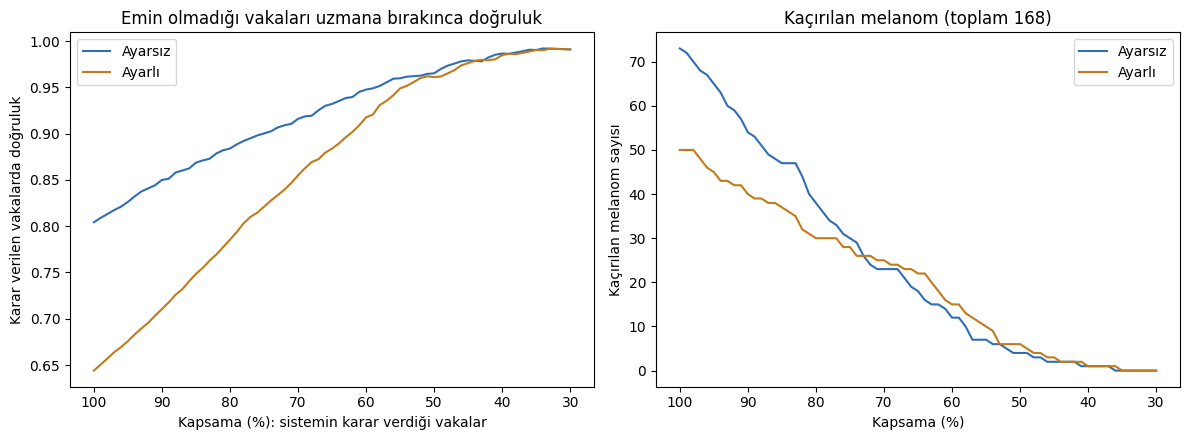

In [8]:
def secici_tahmin(tahmin, p, kapsama_listesi):
    guven = p[np.arange(len(tahmin)), tahmin]
    sira = np.argsort(-guven)                              # en emin olunandan en az emin olunana
    satirlar = []
    for k in kapsama_listesi:
        n = int(round(k * len(tahmin)))
        karar = sira[:n]
        mel_karar = karar[y_test[karar] == MEL]
        satirlar.append({'kapsama': k, 'karar_verilen': n, 'uzmana_giden': len(tahmin) - n,
                         'dogruluk': (tahmin[karar] == y_test[karar]).mean(),
                         'dengeli_dogruluk': balanced_accuracy_score(y_test[karar], tahmin[karar]),
                         'kacirilan_melanom': int((tahmin[mel_karar] != MEL).sum()),
                         'uzmana_giden_melanom': int((y_test == MEL).sum() - len(mel_karar))})
    return pd.DataFrame(satirlar)

kapsamalar = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
toplam_mel = int((y_test == MEL).sum())
print(f'Test kümesinde toplam {toplam_mel} melanom var.\n')
secici = {}
for ad, tah in [('Ayarsız', tahmin_ham), ('Ayarlı', tahmin_ayarli)]:
    secici[ad] = secici_tahmin(tah, p_test, kapsamalar)
    print(f'--- {ad} karar ---')
    print(secici[ad].round(3).to_string(index=False)); print()

ince = np.round(np.arange(1.0, 0.29, -0.01), 2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for ad, tah, renk in [('Ayarsız', tahmin_ham, '#2F6DB5'), ('Ayarlı', tahmin_ayarli, '#C27A1A')]:
    d = secici_tahmin(tah, p_test, ince)
    ax[0].plot(d['kapsama'] * 100, d['dogruluk'], label=ad, color=renk)
    ax[1].plot(d['kapsama'] * 100, d['kacirilan_melanom'], label=ad, color=renk)
ax[0].set_xlabel('Kapsama (%): sistemin karar verdiği vakalar'); ax[0].set_ylabel('Karar verilen vakalarda doğruluk')
ax[0].set_title('Emin olmadığı vakaları uzmana bırakınca doğruluk'); ax[0].invert_xaxis(); ax[0].legend()
ax[1].set_xlabel('Kapsama (%)'); ax[1].set_ylabel('Kaçırılan melanom sayısı')
ax[1].set_title(f'Kaçırılan melanom (toplam {toplam_mel})'); ax[1].invert_xaxis(); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{PROJE}/results/03_uzmana_yonlendirme.png', dpi=150); plt.show()

## 6. Grad-CAM: model nereye bakıyor?
**Grad-CAM**, modelin son evrişim katmanındaki hangi bölgelerin kararı en çok etkilediğini bir ısı haritası olarak gösterir. Kırmızı bölgeler kararda en etkili olanlardır.

İki şey yapıyoruz:
1. **Örnekler:** Doğru bilinen melanom, kaçırılan melanom (ben denmiş), doğru bilinen ben ve yanlış alarm (bene melanom denmiş).
2. **Kısa yol kontrolü:** Her test görüntüsü için ısı haritasının ne kadarının görüntünün **kenar şeridinde** (her kenardan %10'luk dış şerit) olduğu hesaplanır. Lezyonlar genellikle ortada olduğu için kenara yoğun bakan model; cetvel, dermatoskop çerçevesi veya kıl gibi ipuçlarından öğreniyor olabilir. Kenara en çok bakılan görüntüler gösterilir.

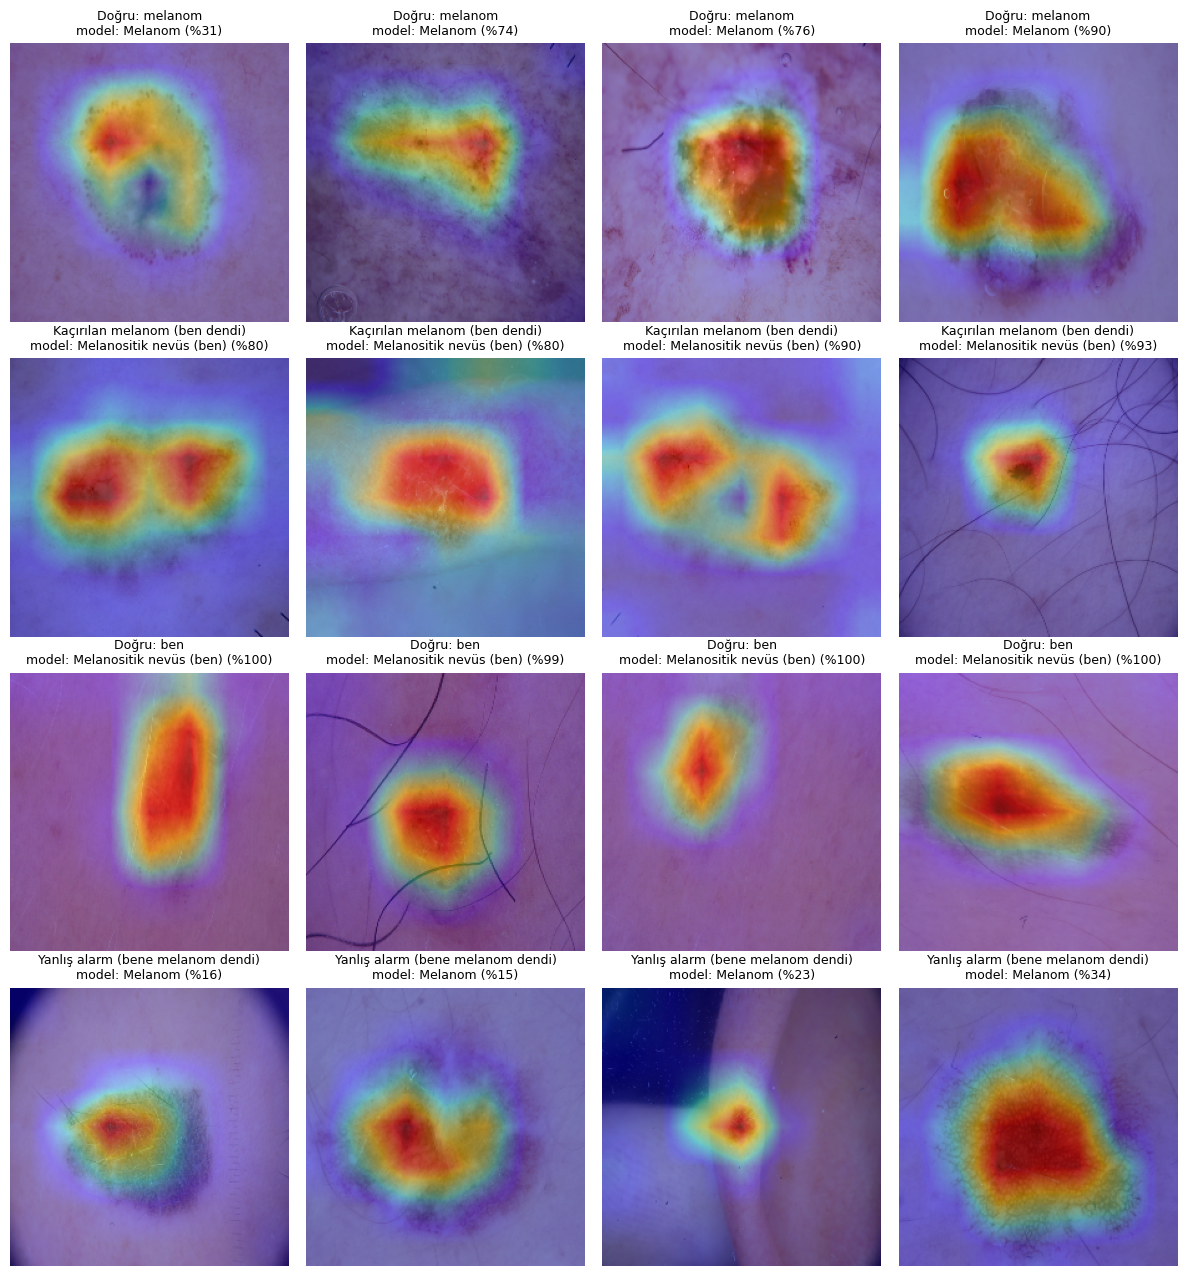

Gruplardaki görüntü sayıları: {'Doğru: melanom': 118, 'Kaçırılan melanom (ben dendi)': 7, 'Doğru: ben': 616, 'Yanlış alarm (bene melanom dendi)': 161}


In [9]:
cam_modeli = keras.Model(model.inputs, [model.get_layer('top_activation').output, model.output])

def gradcam(goruntu, sinif):
    x = tf.convert_to_tensor(goruntu[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        evrisim, logit = cam_modeli(x, training=False)
        skor = tf.cast(logit[:, sinif], tf.float32)
    grad = tf.cast(tape.gradient(skor, evrisim), tf.float32)
    evrisim = tf.cast(evrisim, tf.float32)
    agirlik = tf.reduce_mean(grad, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(evrisim * agirlik[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]

def goruntu_yukle(i):
    return oku(test.loc[i, 'path']).numpy()

def ciz(ax, i, sinif, baslik):
    g = goruntu_yukle(i)
    ax.imshow(np.clip(g, 0, 255).astype('uint8'))
    ax.imshow(gradcam(g, sinif), cmap='jet', alpha=0.4)
    ax.set_title(baslik, fontsize=9); ax.axis('off')

gruplar = {
    'Doğru: melanom': np.where((y_test == MEL) & (tahmin_ayarli == MEL))[0],
    'Kaçırılan melanom (ben dendi)': np.where((y_test == MEL) & (tahmin_ayarli == SINIFLAR.index('nv')))[0],
    'Doğru: ben': np.where((y_test == SINIFLAR.index('nv')) & (tahmin_ayarli == SINIFLAR.index('nv')))[0],
    'Yanlış alarm (bene melanom dendi)': np.where((y_test == SINIFLAR.index('nv')) & (tahmin_ayarli == MEL))[0],
}
fig, eksen = plt.subplots(len(gruplar), 4, figsize=(12, 3.2 * len(gruplar)))
for r, (ad, ix) in enumerate(gruplar.items()):
    secim = rng.choice(ix, size=min(4, len(ix)), replace=False) if len(ix) else []
    for c in range(4):
        ax = eksen[r, c]
        if c < len(secim):
            i = int(secim[c])
            ciz(ax, i, int(tahmin_ayarli[i]), f'{ad}\nmodel: {SINIF_ADI[SINIFLAR[tahmin_ayarli[i]]]} (%{100 * p_test[i, tahmin_ayarli[i]]:.0f})')
        else:
            ax.axis('off')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/03_gradcam_ornekler.png', dpi=120); plt.show()
print('Gruplardaki görüntü sayıları:', {k: len(v) for k, v in gruplar.items()})

Süre: 18.9 dk
Kenar şeridi görüntü alanının %35'ini kaplıyor.
Isı haritasının kenardaki payı: ortanca %16, görüntülerin %6'inde kenar payı alan payından büyük.


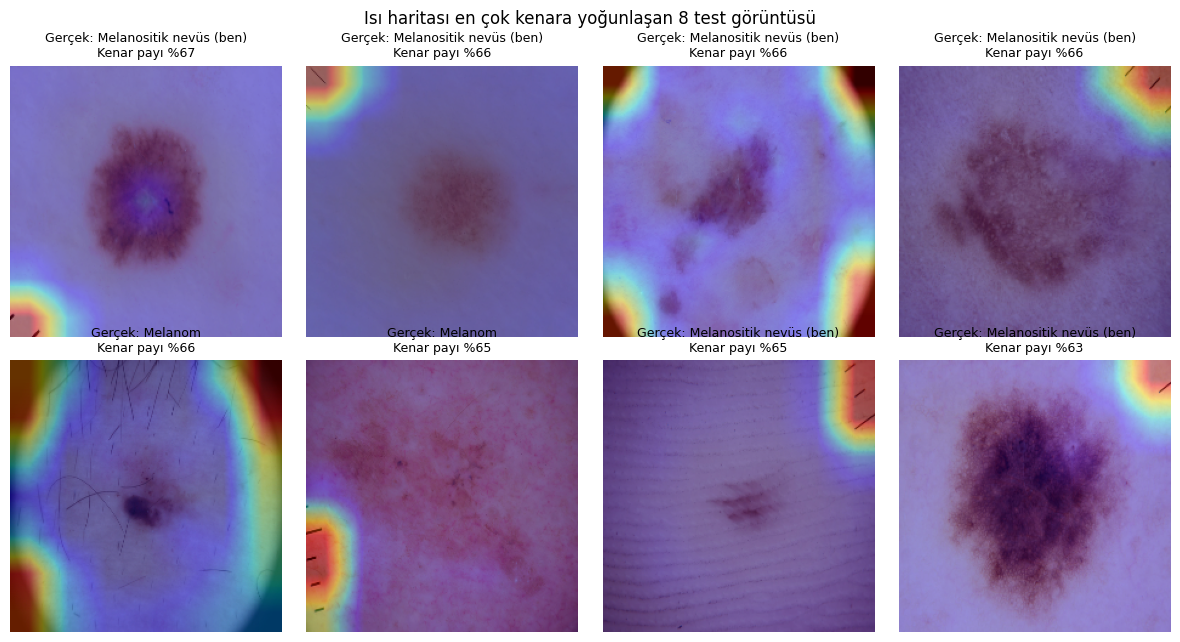

In [10]:
# Kısa yol kontrolü: ısı haritasının kenar şeridindeki payı
kenar = int(0.10 * IMG)
maske = np.ones((IMG, IMG), bool); maske[kenar:-kenar, kenar:-kenar] = False
kenar_alan_payi = maske.mean()

t0 = time.time()
kenar_payi = np.zeros(len(test))
for i in range(len(test)):
    cam = gradcam(goruntu_yukle(i), int(tahmin_ayarli[i]))
    kenar_payi[i] = cam[maske].sum() / (cam.sum() + 1e-8)
print(f'Süre: {(time.time() - t0) / 60:.1f} dk')
print(f'Kenar şeridi görüntü alanının %{100 * kenar_alan_payi:.0f}\'ini kaplıyor.')
print(f'Isı haritasının kenardaki payı: ortanca %{100 * np.median(kenar_payi):.0f}, '
      f'görüntülerin %{100 * (kenar_payi > kenar_alan_payi).mean():.0f}\'inde kenar payı alan payından büyük.')

en_kenar = np.argsort(-kenar_payi)[:8]
fig, eksen = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, i in zip(eksen.ravel(), en_kenar):
    ciz(ax, int(i), int(tahmin_ayarli[i]),
        f'Gerçek: {SINIF_ADI[SINIFLAR[y_test[i]]]}\nKenar payı %{100 * kenar_payi[i]:.0f}')
plt.suptitle('Isı haritası en çok kenara yoğunlaşan 8 test görüntüsü'); plt.tight_layout()
plt.savefig(f'{PROJE}/results/03_gradcam_kenar.png', dpi=120); plt.show()

## 7. Sonuçları kaydet

In [11]:
cikti = {
    'model': MODEL_ADI, 'img': IMG, 'siniflar': SINIFLAR,
    'sicaklik_T': T, 'tau': TAU,
    'dogrulama_ece_once': ece(p_dog_ham, y_dog), 'dogrulama_ece_sonra': ece(p_dog_kal, y_dog),
    'test_ece_once': ece(softmax(logit_test), y_test), 'test_ece_sonra': ece(p_test, y_test),
    'test_ayarsiz': {k: float(v) for k, v in test_ham.items()},
    'test_ayarli': {k: float(v) for k, v in test_ayarli.items()},
    'guven_araliklari': guven_araliklari.to_dict(orient='records'),
    'uzmana_yonlendirme': {k: v.to_dict(orient='records') for k, v in secici.items()},
    'gradcam_kenar_payi_ortanca': float(np.median(kenar_payi)),
    'gradcam_kenar_alan_payi': float(kenar_alan_payi),
}
with open(f'{PROJE}/results/03_test_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump(cikti, f, ensure_ascii=False, indent=2, default=float)
pd.DataFrame({'image_id': test['image_id'], 'lesion_id': test['lesion_id'], 'gercek': [SINIFLAR[i] for i in y_test],
              'tahmin_ayarsiz': [SINIFLAR[i] for i in tahmin_ham], 'tahmin_ayarli': [SINIFLAR[i] for i in tahmin_ayarli],
              'guven_ayarli': p_test[np.arange(len(test)), tahmin_ayarli], 'gradcam_kenar_payi': kenar_payi,
              **{f'p_{s}': p_test[:, i] for i, s in enumerate(SINIFLAR)}}).to_csv(
    f'{PROJE}/results/03_test_tahminleri.csv', index=False)

print('Kaydedildi:')
for p in [f'models/{MODEL_ADI}_test_logit.npy', 'results/03_test_sonuclari.json', 'results/03_test_tahminleri.csv',
          'results/03_kalibrasyon_dogrulama.png', 'results/03_kalibrasyon_test.png', 'results/03_test_karisiklik_matrisi.png',
          'results/03_uzmana_yonlendirme.png', 'results/03_gradcam_ornekler.png', 'results/03_gradcam_kenar.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  models/cnn_b0_v3_test_logit.npy ✓
  results/03_test_sonuclari.json ✓
  results/03_test_tahminleri.csv ✓
  results/03_kalibrasyon_dogrulama.png ✓
  results/03_kalibrasyon_test.png ✓
  results/03_test_karisiklik_matrisi.png ✓
  results/03_uzmana_yonlendirme.png ✓
  results/03_gradcam_ornekler.png ✓
  results/03_gradcam_kenar.png ✓
